# Notebook 3 — Baseline ML Models (R3)
Rice Variety Classification | F20DL 2026/2027

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression, Perceptron
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, ConfusionMatrixDisplay

df = pd.read_csv('../data/tabular/rice_cammeo_osmancik.csv')
feature_names = [c for c in df.columns if c != 'Class']
X = df[feature_names].values
le = LabelEncoder()
y = le.fit_transform(df['Class'])
CLASS_NAMES = list(le.classes_)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

CV = 5  # cross-validation folds used in GridSearchCV
results = {}
print(f"Train: {len(X_train)}  Test: {len(X_test)}  GridSearchCV folds: {CV}")

Train: 3048  Test: 762  GridSearchCV folds: 5


## 1. Decision Tree

Best params: {'criterion': 'entropy', 'max_depth': 3, 'min_samples_split': 2}  CV F1: 0.9271
              precision    recall  f1-score   support

      Cammeo       0.94      0.87      0.90       326
    Osmancik       0.91      0.96      0.93       436

    accuracy                           0.92       762
   macro avg       0.92      0.91      0.92       762
weighted avg       0.92      0.92      0.92       762



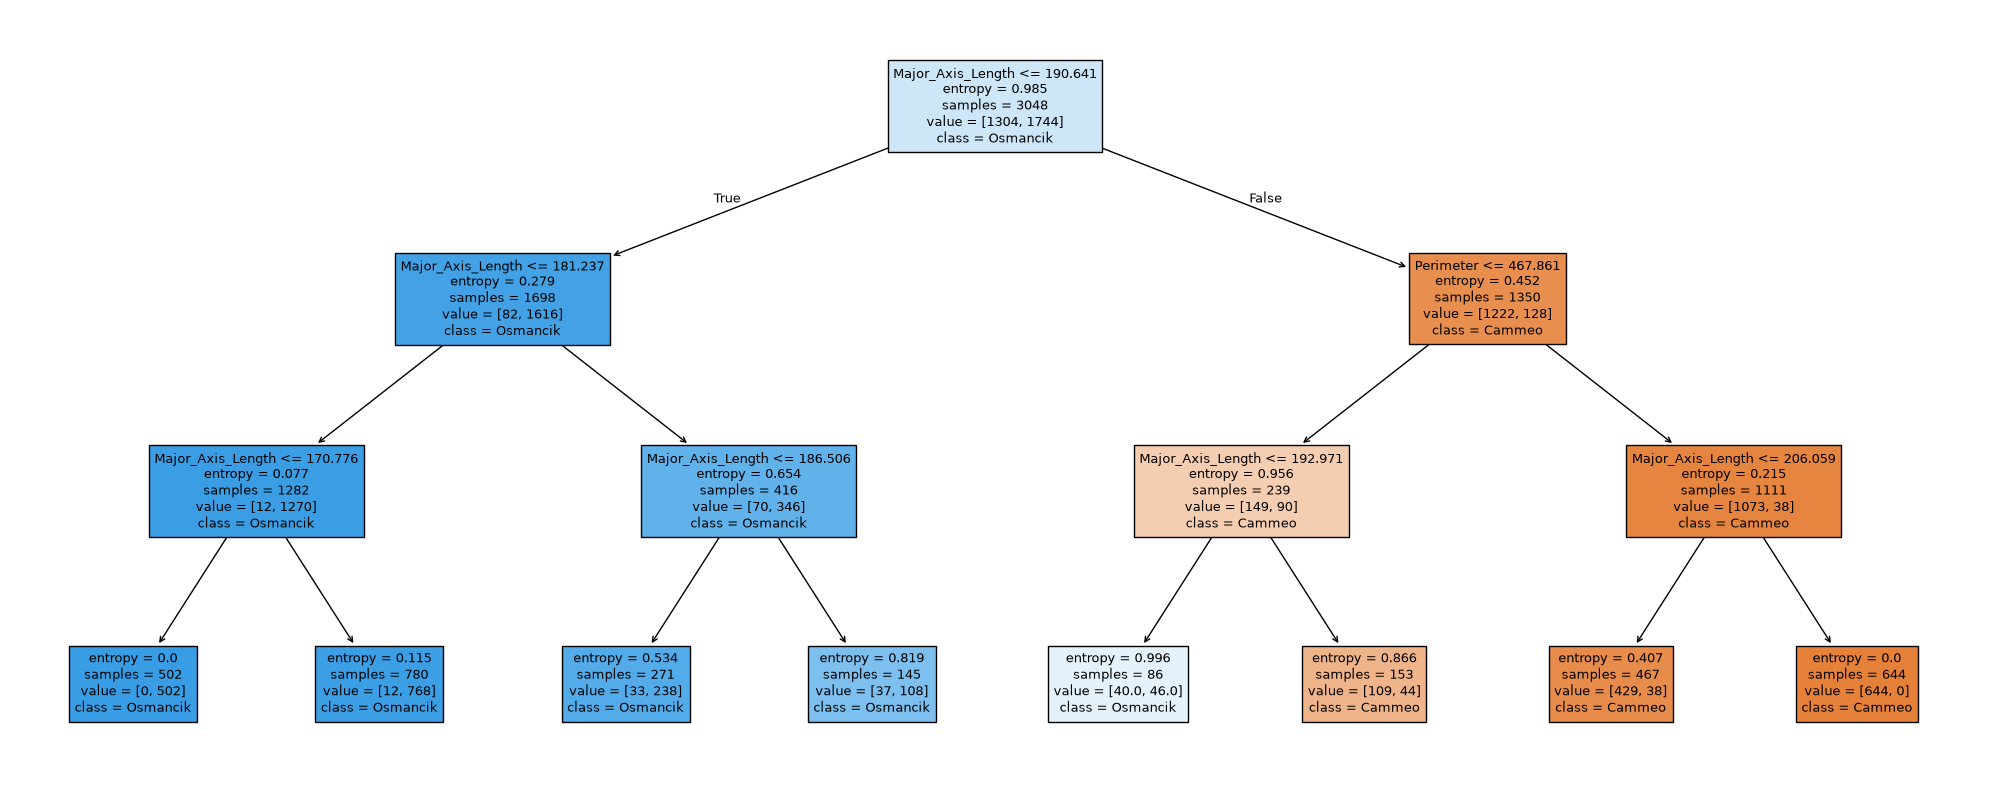

In [2]:
param_grid_dt = {'max_depth': [3, 5, 7, 10, None], 'min_samples_split': [2, 5, 10], 'criterion': ['gini', 'entropy']}
gs_dt = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid_dt, cv=CV, scoring='f1_weighted', n_jobs=-1)
gs_dt.fit(X_train, y_train)
dt = gs_dt.best_estimator_
print(f"Best params: {gs_dt.best_params_}  CV F1: {gs_dt.best_score_:.4f}")

y_pred_dt = dt.predict(X_test)
results['Decision Tree'] = {
    'Accuracy':  accuracy_score(y_test, y_pred_dt),
    'Precision': precision_score(y_test, y_pred_dt, average='weighted'),
    'Recall':    recall_score(y_test, y_pred_dt, average='weighted'),
    'F1':        f1_score(y_test, y_pred_dt, average='weighted'),
}
print(classification_report(y_test, y_pred_dt, target_names=CLASS_NAMES))

plt.figure(figsize=(20, 8))
plot_tree(dt, filled=True, feature_names=feature_names, class_names=CLASS_NAMES, fontsize=9)
plt.tight_layout()
plt.savefig('../results/decision_tree.png', dpi=100, bbox_inches='tight')
plt.show()

## 2. Naive Bayes

In [3]:
param_grid_nb = {'var_smoothing': np.logspace(-12, 0, 13)}
gs_nb = GridSearchCV(GaussianNB(), param_grid_nb, cv=CV, scoring='f1_weighted', n_jobs=-1)
gs_nb.fit(X_train_sc, y_train)
nb = gs_nb.best_estimator_
print(f"Best params: {gs_nb.best_params_}  CV F1: {gs_nb.best_score_:.4f}")

y_pred_nb = nb.predict(X_test_sc)
results['Naive Bayes'] = {
    'Accuracy':  accuracy_score(y_test, y_pred_nb),
    'Precision': precision_score(y_test, y_pred_nb, average='weighted'),
    'Recall':    recall_score(y_test, y_pred_nb, average='weighted'),
    'F1':        f1_score(y_test, y_pred_nb, average='weighted'),
}
print(classification_report(y_test, y_pred_nb, target_names=CLASS_NAMES))

Best params: {'var_smoothing': np.float64(1e-12)}  CV F1: 0.9235
              precision    recall  f1-score   support

      Cammeo       0.90      0.85      0.87       326
    Osmancik       0.89      0.93      0.91       436

    accuracy                           0.90       762
   macro avg       0.90      0.89      0.89       762
weighted avg       0.90      0.90      0.89       762



## 3. Logistic Regression

In [4]:
param_grid_lr = {'C': [0.01, 0.1, 1, 10, 100], 'solver': ['lbfgs', 'liblinear'], 'penalty': ['l2']}
gs_lr = GridSearchCV(LogisticRegression(max_iter=2000, random_state=42), param_grid_lr, cv=CV, scoring='f1_weighted', n_jobs=-1)
gs_lr.fit(X_train_sc, y_train)
lr = gs_lr.best_estimator_
print(f"Best params: {gs_lr.best_params_}  CV F1: {gs_lr.best_score_:.4f}")

y_pred_lr = lr.predict(X_test_sc)
results['Logistic Regression'] = {
    'Accuracy':  accuracy_score(y_test, y_pred_lr),
    'Precision': precision_score(y_test, y_pred_lr, average='weighted'),
    'Recall':    recall_score(y_test, y_pred_lr, average='weighted'),
    'F1':        f1_score(y_test, y_pred_lr, average='weighted'),
}
print(classification_report(y_test, y_pred_lr, target_names=CLASS_NAMES))

Best params: {'C': 100, 'penalty': 'l2', 'solver': 'lbfgs'}  CV F1: 0.9353
              precision    recall  f1-score   support

      Cammeo       0.93      0.88      0.90       326
    Osmancik       0.91      0.95      0.93       436

    accuracy                           0.92       762
   macro avg       0.92      0.91      0.92       762
weighted avg       0.92      0.92      0.92       762



/Users/kamal/Downloads/f20dl-rice-classification/.venv/lib/python3.15/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/kamal/Downloads/f20dl-rice-classification/.venv/lib/python3.15/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=N

## 4. Perceptron

In [5]:
param_grid_perc = {'alpha': [0.0001, 0.001, 0.01, 0.1], 'max_iter': [500, 1000, 2000], 'tol': [1e-4, 1e-3]}
gs_perc = GridSearchCV(Perceptron(random_state=42), param_grid_perc, cv=CV, scoring='f1_weighted', n_jobs=-1)
gs_perc.fit(X_train_sc, y_train)
perc = gs_perc.best_estimator_
print(f"Best params: {gs_perc.best_params_}  CV F1: {gs_perc.best_score_:.4f}")

y_pred_perc = perc.predict(X_test_sc)
results['Perceptron'] = {
    'Accuracy':  accuracy_score(y_test, y_pred_perc),
    'Precision': precision_score(y_test, y_pred_perc, average='weighted', zero_division=0),
    'Recall':    recall_score(y_test, y_pred_perc, average='weighted', zero_division=0),
    'F1':        f1_score(y_test, y_pred_perc, average='weighted', zero_division=0),
}
print(classification_report(y_test, y_pred_perc, target_names=CLASS_NAMES, zero_division=0))

Best params: {'alpha': 0.0001, 'max_iter': 500, 'tol': 0.0001}  CV F1: 0.9013
              precision    recall  f1-score   support

      Cammeo       0.89      0.87      0.88       326
    Osmancik       0.90      0.92      0.91       436

    accuracy                           0.90       762
   macro avg       0.90      0.90      0.90       762
weighted avg       0.90      0.90      0.90       762



## 5. k-Nearest Neighbours

In [6]:
param_grid_knn = {'n_neighbors': [3, 5, 7, 11, 15, 21], 'weights': ['uniform', 'distance'], 'metric': ['euclidean', 'manhattan']}
gs_knn = GridSearchCV(KNeighborsClassifier(), param_grid_knn, cv=CV, scoring='f1_weighted', n_jobs=-1)
gs_knn.fit(X_train_sc, y_train)
knn = gs_knn.best_estimator_
print(f"Best params: {gs_knn.best_params_}  CV F1: {gs_knn.best_score_:.4f}")

y_pred_knn = knn.predict(X_test_sc)
results['kNN'] = {
    'Accuracy':  accuracy_score(y_test, y_pred_knn),
    'Precision': precision_score(y_test, y_pred_knn, average='weighted'),
    'Recall':    recall_score(y_test, y_pred_knn, average='weighted'),
    'F1':        f1_score(y_test, y_pred_knn, average='weighted'),
}
print(classification_report(y_test, y_pred_knn, target_names=CLASS_NAMES))

Best params: {'metric': 'euclidean', 'n_neighbors': 11, 'weights': 'uniform'}  CV F1: 0.9301
              precision    recall  f1-score   support

      Cammeo       0.91      0.89      0.90       326
    Osmancik       0.92      0.93      0.92       436

    accuracy                           0.91       762
   macro avg       0.91      0.91      0.91       762
weighted avg       0.91      0.91      0.91       762



## 6. Ensemble — Random Forest & Gradient Boosting

In [7]:
param_grid_rf = {'n_estimators': [100, 200], 'max_depth': [None, 10, 20], 'min_samples_split': [2, 5], 'max_features': ['sqrt', 'log2']}
gs_rf = GridSearchCV(RandomForestClassifier(random_state=42), param_grid_rf, cv=CV, scoring='f1_weighted', n_jobs=-1)
gs_rf.fit(X_train, y_train)
rf = gs_rf.best_estimator_
print(f"Random Forest best params: {gs_rf.best_params_}  CV F1: {gs_rf.best_score_:.4f}")

y_pred_rf = rf.predict(X_test)
results['Random Forest'] = {
    'Accuracy':  accuracy_score(y_test, y_pred_rf),
    'Precision': precision_score(y_test, y_pred_rf, average='weighted'),
    'Recall':    recall_score(y_test, y_pred_rf, average='weighted'),
    'F1':        f1_score(y_test, y_pred_rf, average='weighted'),
}
print(classification_report(y_test, y_pred_rf, target_names=CLASS_NAMES))

param_grid_gb = {'n_estimators': [100, 200], 'learning_rate': [0.05, 0.1, 0.2], 'max_depth': [3, 5], 'subsample': [0.8, 1.0]}
gs_gb = GridSearchCV(GradientBoostingClassifier(random_state=42), param_grid_gb, cv=CV, scoring='f1_weighted', n_jobs=-1)
gs_gb.fit(X_train, y_train)
gb = gs_gb.best_estimator_
print(f"Gradient Boosting best params: {gs_gb.best_params_}  CV F1: {gs_gb.best_score_:.4f}")

y_pred_gb = gb.predict(X_test)
results['Gradient Boosting'] = {
    'Accuracy':  accuracy_score(y_test, y_pred_gb),
    'Precision': precision_score(y_test, y_pred_gb, average='weighted'),
    'Recall':    recall_score(y_test, y_pred_gb, average='weighted'),
    'F1':        f1_score(y_test, y_pred_gb, average='weighted'),
}
print(classification_report(y_test, y_pred_gb, target_names=CLASS_NAMES))

Random Forest best params: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_split': 5, 'n_estimators': 200}  CV F1: 0.9275
              precision    recall  f1-score   support

      Cammeo       0.93      0.87      0.90       326
    Osmancik       0.91      0.95      0.93       436

    accuracy                           0.92       762
   macro avg       0.92      0.91      0.91       762
weighted avg       0.92      0.92      0.92       762



Gradient Boosting best params: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100, 'subsample': 1.0}  CV F1: 0.9308
              precision    recall  f1-score   support

      Cammeo       0.92      0.88      0.90       326
    Osmancik       0.91      0.94      0.93       436

    accuracy                           0.91       762
   macro avg       0.92      0.91      0.91       762
weighted avg       0.91      0.91      0.91       762



## 7. Model Comparison Summary

                     Accuracy  Precision  Recall      F1
Decision Tree          0.9199     0.9210  0.9199  0.9195
Logistic Regression    0.9186     0.9189  0.9186  0.9183
Random Forest          0.9160     0.9164  0.9160  0.9157
Gradient Boosting      0.9147     0.9149  0.9147  0.9144
kNN                    0.9121     0.9120  0.9121  0.9119
Perceptron             0.8990     0.8988  0.8990  0.8988
Naive Bayes            0.8950     0.8953  0.8950  0.8945


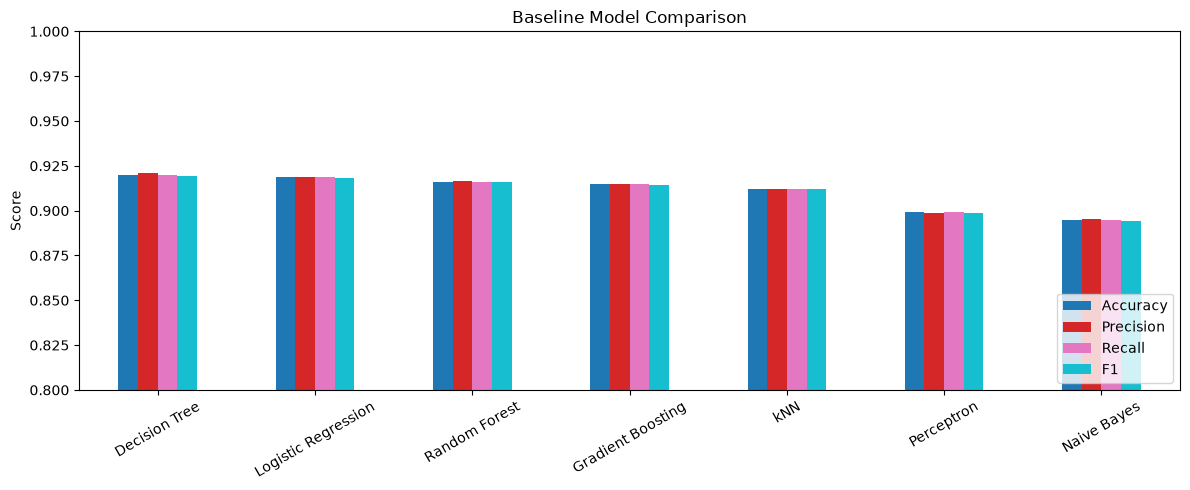

In [8]:
summary = pd.DataFrame(results).T.round(4)
summary = summary.sort_values('F1', ascending=False)
print(summary.to_string())
summary.to_csv('../results/baseline_comparison.csv')

ax = summary[['Accuracy', 'Precision', 'Recall', 'F1']].plot(
    kind='bar', figsize=(12, 5), ylim=(0.8, 1.0), rot=30, colormap='tab10'
)
ax.set_title('Baseline Model Comparison')
ax.set_ylabel('Score')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('../results/baseline_comparison.png', dpi=100)
plt.show()

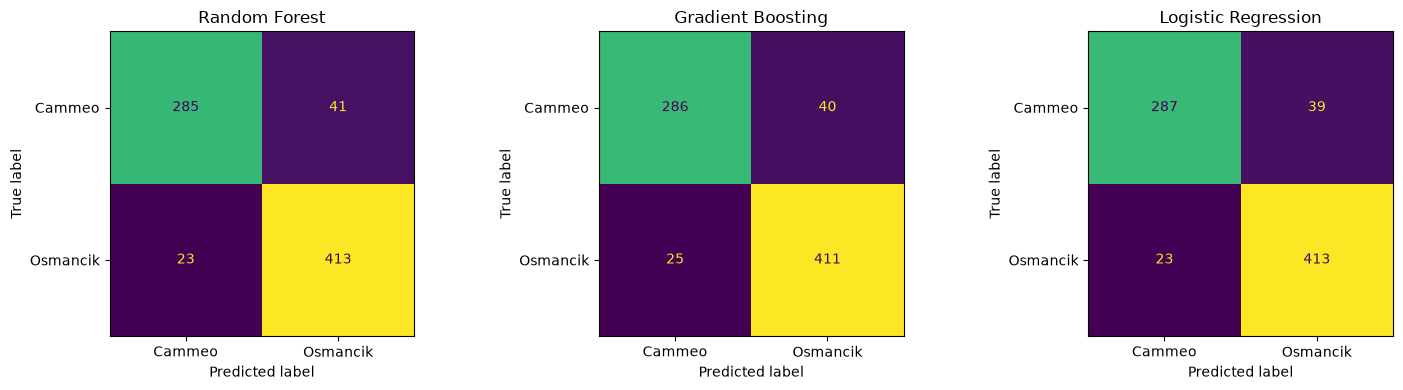

In [9]:
# Confusion matrices for top 3 models
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, preds) in zip(axes, [
    ('Random Forest', y_pred_rf),
    ('Gradient Boosting', y_pred_gb),
    ('Logistic Regression', y_pred_lr),
]):
    ConfusionMatrixDisplay.from_predictions(y_test, preds, display_labels=CLASS_NAMES, ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.savefig('../results/confusion_matrices.png', dpi=100)
plt.show()